In [1]:
# %%
import pandas as pd
import numpy as np
import re
import joblib
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Dropout, Concatenate, Bidirectional, GaussianNoise, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2

In [2]:
# %%
# Load and clean data
df = pd.read_excel("C:/Users/johnc/OneDrive/Desktop/2nd Year 2nd Sem/Machine Learning/Final Project/data/forex_news.xlsx")
df.dropna(how='all', inplace=True)
df = df[df['impact'].astype(str).str.strip().str.lower() != 'holiday']

In [3]:
def parse_percentage(val):
    if pd.isna(val):
        return np.nan
    val = str(val).strip().replace(",", "").replace("<", "")
    if not val.endswith('%'):
        return np.nan
    try:
        return float(val.replace("%", ""))
    except:
        return np.nan

df['actual'] = df['actual'].apply(parse_percentage)
df['forecast'] = df['forecast'].apply(parse_percentage)
df.dropna(subset=['actual', 'forecast'], inplace=True)

In [4]:
# Feature engineering
df['impact_clean'] = df['impact'].astype(str).str.strip().str.lower()
impact_mapping = {'low': 1, 'medium': 2, 'high': 3}
df['impact_score'] = df['impact_clean'].map(impact_mapping)
df['headline'] = df['event_title'].astype(str).str.lower().str.replace(r'[^\w\s]', '', regex=True)
df.dropna(subset=['headline', 'impact_score'], inplace=True)
df.drop_duplicates(subset=['headline', 'forecast', 'impact_score', 'actual'], inplace=True)

# Filter out overly predictable headlines
headline_stats = df.groupby('headline')['actual'].mean()
valid_headlines = headline_stats[headline_stats.notna()].index
df = df[df['headline'].isin(valid_headlines)]

In [5]:
# Features and labels
X_text = df['headline'].values
X_numeric = df[['forecast', 'impact_score']].values
y_actual = df['actual'].values  # target: actual %

In [6]:
# Tokenization
tokenizer = Tokenizer(num_words=20000, oov_token='<OOV>')
tokenizer.fit_on_texts(X_text)
X_seq = tokenizer.texts_to_sequences(X_text)
max_len = 80
X_pad = pad_sequences(X_seq, maxlen=max_len, padding='post')
joblib.dump(tokenizer, "tokenizer.pkl")

# Scale numeric inputs
scaler = StandardScaler()
X_numeric_scaled = scaler.fit_transform(X_numeric)
joblib.dump(scaler, "scaler.pkl")

['scaler.pkl']

In [7]:
# Train/test split using GroupShuffleSplit to avoid leakage
splitter = GroupShuffleSplit(test_size=0.2, random_state=42)
groups = df['headline']
for train_idx, test_idx in splitter.split(X_pad, y_actual, groups):
    X_train_pad, X_test_pad = X_pad[train_idx], X_pad[test_idx]
    X_train_num, X_test_num = X_numeric_scaled[train_idx], X_numeric_scaled[test_idx]
    y_train, y_test = y_actual[train_idx], y_actual[test_idx]

In [8]:
# Build LSTM regression model
text_input = Input(shape=(max_len,), name='text_input')
x = Embedding(input_dim=20000, output_dim=128)(text_input)
x = GaussianNoise(0.1)(x)
x = Bidirectional(LSTM(128, dropout=0.2, recurrent_dropout=0.2))(x)
x = Dropout(0.2)(x)

num_input = Input(shape=(2,), name='numeric_input')
num_noisy = GaussianNoise(0.1)(num_input)

combined = Concatenate()([x, num_noisy])
z = Dense(128, activation='relu', kernel_regularizer=l2(0.001))(combined)
z = BatchNormalization()(z)
z = Dropout(0.2)(z)
output = Dense(1, activation='linear')(z)  # Regression output

model = Model(inputs=[text_input, num_input], outputs=output)
opt = Adam(learning_rate=0.0005)
model.compile(loss='mean_squared_error', optimizer=opt, metrics=['mae'])
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ text_input          │ (None, 80)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 80, 128)   │  2,560,000 │ text_input[0][0]  │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gaussian_noise      │ (None, 80, 128)   │          0 │ embedding[0][0]   │
│ (GaussianNoise)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 256)       │    263,168 │ gaussian_noise[0… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ numeric_input       │ (None, 2)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 256)       │          0 │ bidirectional[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gaussian_noise_1    │ (None, 2)         │          0 │ numeric_input[0]… │
│ (GaussianNoise)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 258)       │          0 │ dropout[0][0],    │
│ (Concatenate)       │                   │            │ gaussian_noise_1… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 128)       │     33,152 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 128)       │        512 │ dense[0][0]       │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 128)       │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 1)         │        129 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,856,961 (10.90 MB)

 Trainable params: 2,856,705 (10.90 MB)

 Non-trainable params: 256 (1.00 KB)

In [9]:
# Train
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, min_delta=0.0005)
history = model.fit(
    [X_train_pad, X_train_num], y_train,
    validation_split=0.2,
    epochs=30,
    batch_size=16,
    callbacks=[early_stop]
)

Epoch 1/30
808/808 ━━━━━━━━━━━━━━━━━━━━ 403s 462ms/step - loss: 120.3630 - mae: 4.5985 - val_loss: 18.6275 - val_mae: 2.0818
Epoch 2/30
808/808 ━━━━━━━━━━━━━━━━━━━━ 440s 545ms/step - loss: 34.2175 - mae: 3.9775 - val_loss: 34.3130 - val_mae: 3.4135
Epoch 3/30
808/808 ━━━━━━━━━━━━━━━━━━━━ 395s 489ms/step - loss: 27.4217 - mae: 3.7236 - val_loss: 35.9756 - val_mae: 2.3835
Epoch 4/30
808/808 ━━━━━━━━━━━━━━━━━━━━ 451s 499ms/step - loss: 24.8581 - mae: 3.6898 - val_loss: 18.2408 - val_mae: 2.1993
Epoch 5/30
808/808 ━━━━━━━━━━━━━━━━━━━━ 370s 458ms/step - loss: 26.5376 - mae: 3.7399 - val_loss: 30.3241 - val_mae: 2.7189
Epoch 6/30
808/808 ━━━━━━━━━━━━━━━━━━━━ 322s 398ms/step - loss: 23.1713 - mae: 3.5803 - val_loss: 33.4796 - val_mae: 2.4999
Epoch 7/30
808/808 ━━━━━━━━━━━━━━━━━━━━ 425s 526ms/step - loss: 25.7551 - mae: 3.7304 - val_loss: 28.3202 - val_mae: 2.8485
Epoch 8/30
808/808 ━━━━━━━━━━━━━━━━━━━━ 399s 494ms/step - loss: 24.4078 - mae: 3.6240 - val_loss: 20.2578 - val_mae: 2.4246
Epoch 9

In [14]:
# Evaluate
y_pred = model.predict([X_test_pad, X_test_num]).flatten()
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(((y_test - y_pred) ** 2).mean())
print("\nEvaluation Matrix:")
print(f"\n🎯 Mean Absolute Error: {mae:.4f}")
print(f"🎯 Root Mean Squared Error: {rmse:.4f}")

96/96 ━━━━━━━━━━━━━━━━━━━━ 56s 565ms/step

Evaluation Matrix:

🎯 Mean Absolute Error: 1.5128
🎯 Root Mean Squared Error: 2.0708


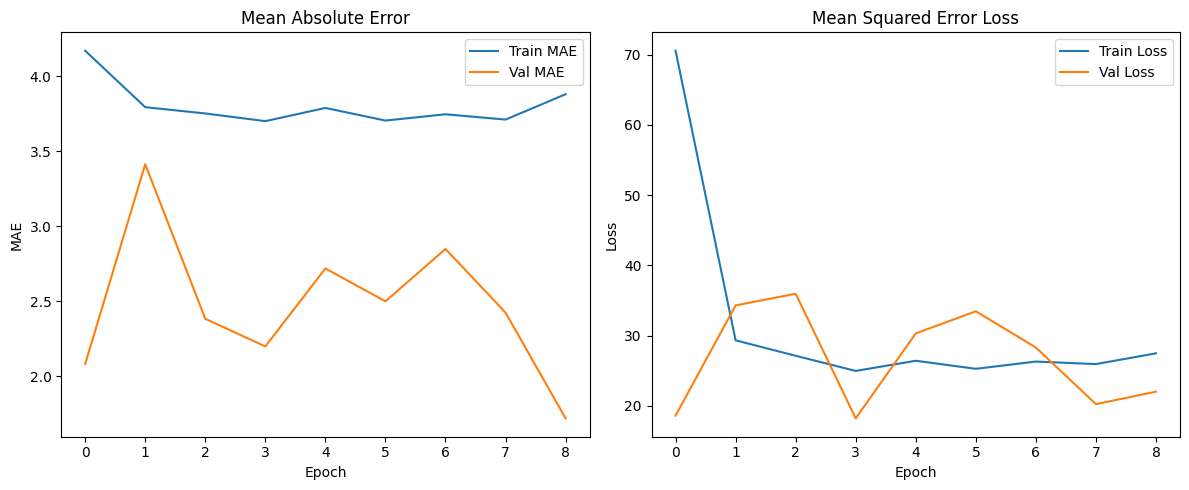

In [11]:
# Visualize
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['mae'], label='Train MAE')
plt.plot(history.history['val_mae'], label='Val MAE')
plt.title('Mean Absolute Error')
plt.xlabel('Epoch')
plt.ylabel('MAE')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Mean Squared Error Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()

In [ ]:
model.save("regression_forex_price.h5")